<a href="https://colab.research.google.com/github/KhalisTk/Water-Potability-Prediction/blob/main/Water_Quality_Potability.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**CHAPTER 5: Data Analysis**

EDA PROCESS

1. BASIC INFO
Rows    : 3276
Columns : 10

ph                 float64
Hardness           float64
Solids             float64
Chloramines        float64
Sulfate            float64
Conductivity       float64
Organic_carbon     float64
Trihalomethanes    float64
Turbidity          float64
Potability           int64
dtype: object

         ph    Hardness        Solids  Chloramines     Sulfate  Conductivity  \
0       NaN  204.890455  20791.318981     7.300212  368.516441    564.308654   
1  3.716080  129.422921  18630.057858     6.635246         NaN    592.885359   
2  8.099124  224.236259  19909.541732     9.275884         NaN    418.606213   
3  8.316766  214.373394  22018.417441     8.059332  356.886136    363.266516   
4  9.092223  181.101509  17978.986339     6.546600  310.135738    398.410813   

   Organic_carbon  Trihalomethanes  Turbidity  Potability  
0       10.379783        86.990970   2.963135           0  
1       15.180013        56.329076   4.500656           0  
2       16.

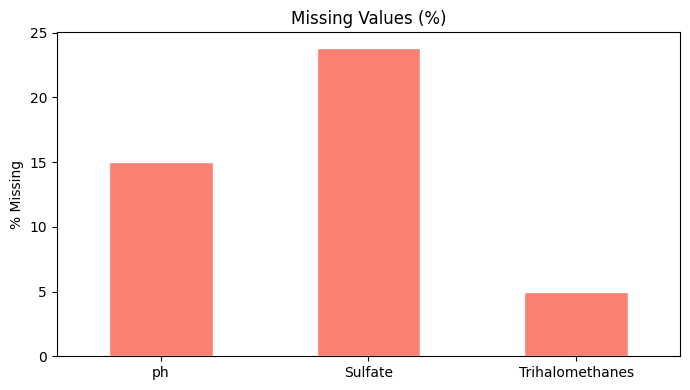


4. TARGET DISTRIBUTION
Potability
Not Potable    1998
Potable        1278
Name: count, dtype: int64


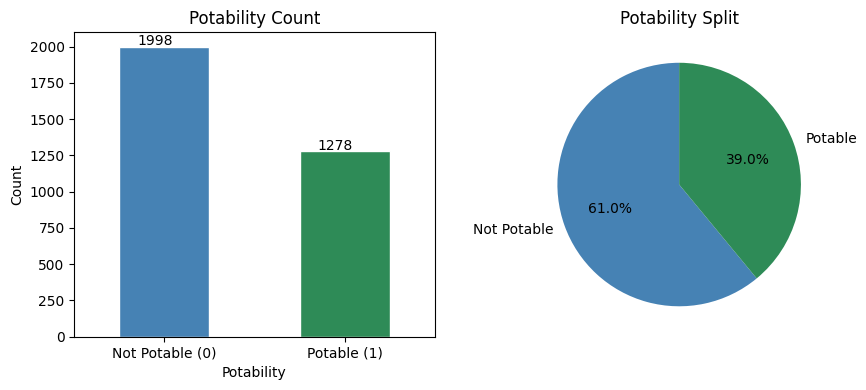


5. Feature DISTRIBUTION
Potability
Not Potable    1998
Potable        1278
Name: count, dtype: int64


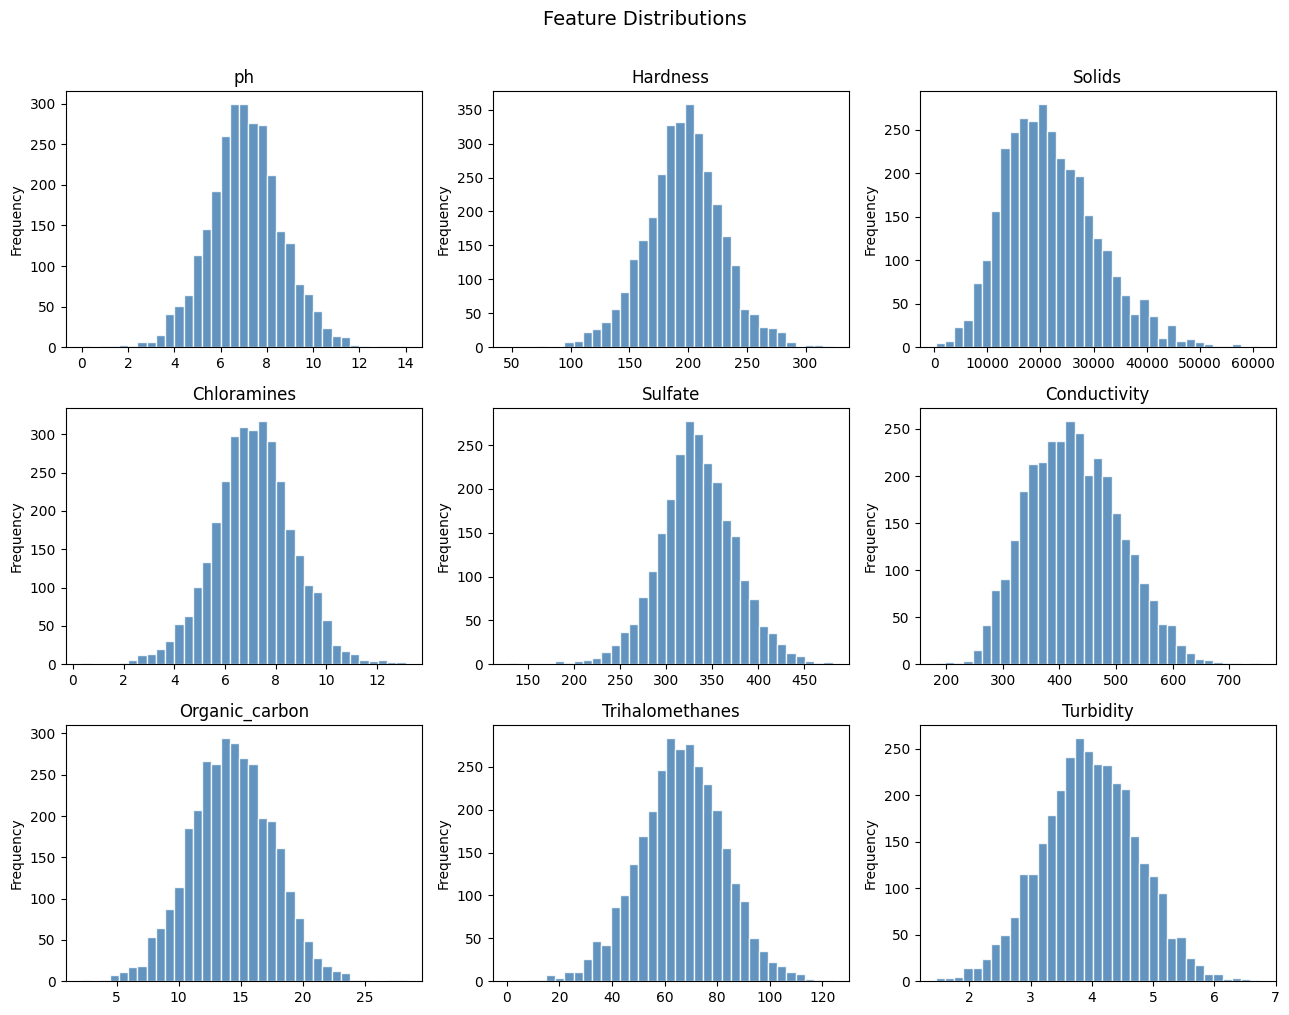

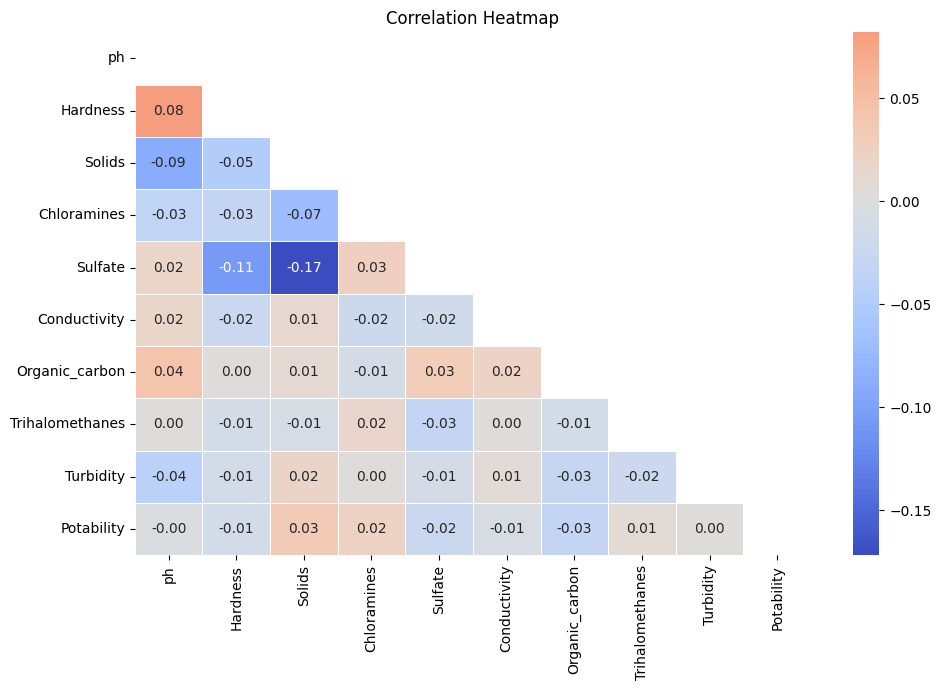


EDA complete ✓


In [ ]:
# EXPERIMENTAL DATA ANALYSISS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# LOAD DATA
FILE_PATH = "water_potability.csv"
df = pd.read_csv(FILE_PATH)

# 1. BASIC INFO
print("=" * 50)
print("1. BASIC INFO")
print("=" * 50)
print(f"Rows    : {df.shape[0]}")
print(f"Columns : {df.shape[1]}")
print()
print(df.dtypes)
print()
print(df.head())

# 2. MISSING VALUES
print("\n" + "=" * 50)
print("3. MISSING VALUES")
print("=" * 50)
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
print(pd.DataFrame({"Count": missing, "Percentage (%)": missing_pct}))

# Bar chart
plt.figure(figsize=(7, 4))
missing_pct[missing_pct > 0].plot(kind="bar", color="salmon", edgecolor="white")
plt.title("Missing Values (%)")
plt.ylabel("% Missing")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3. TARGET DISTRIBUTION
print("\n" + "=" * 50)
print("4. TARGET DISTRIBUTION")
print("=" * 50)
vc = df["Potability"].value_counts()
print(vc.rename({0: "Not Potable", 1: "Potable"}))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
vc.plot(kind="bar", ax=axes[0], color=["steelblue", "seagreen"], edgecolor="white", rot=0)
axes[0].set_title("Potability Count")
axes[0].set_xticklabels(["Not Potable (0)", "Potable (1)"])
axes[0].set_ylabel("Count")
for p in axes[0].patches:
    axes[0].annotate(str(int(p.get_height())), (p.get_x() + 0.1, p.get_height() + 10))

axes[1].pie(vc, labels=["Not Potable", "Potable"], autopct="%1.1f%%",
            colors=["steelblue", "seagreen"], startangle=90)
axes[1].set_title("Potability Split")
plt.tight_layout()
plt.show()

# 4. FEATURE DISTRIBUTIONS (Histograms)
print("\n" + "=" * 50)
print("5. Feature DISTRIBUTION")
print("=" * 50)
vc = df["Potability"].value_counts()
print(vc.rename({0: "Not Potable", 1: "Potable"}))
features = [c for c in df.columns if c != "Potability"]

fig, axes = plt.subplots(3, 3, figsize=(10, 10))
axes = axes.flatten()
for i, col in enumerate(features):
    df[col].dropna().plot(kind="hist", bins=35, ax=axes[i],
                          color="steelblue", edgecolor="white", alpha=0.85)
    axes[i].set_title(col)
plt.suptitle("Feature Distributions", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

# 5. CORRELATION HEATMAP
plt.figure(figsize=(10, 7))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

print("\nEDA complete ✓")


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# DATA PREPROCESSING
import numpy as np
import pandas as pd
import joblib
import os

# STEP 1 — SEPARATE FEATURES & TARGET
X_original = df.drop(columns=["Potability"])
y = df["Potability"]
feature_names = X_original.columns.tolist()
print(f"  Features : {feature_names}")
print(f"  Target   : Potability  (0={sum(y==0)}, 1={sum(y==1)})\n")

# STEP 3 — OUTLIER CLIPPING
X_clipped = X_original.copy()
for col in feature_names:
    low  = X_clipped[col].quantile(0.01)
    high = X_clipped[col].quantile(0.99)
    clipped = X_clipped[col].clip(low, high)
    n_clipped = (X_clipped[col] != clipped).sum()
    X_clipped[col] = clipped
    print(f"  {col:<22}: {n_clipped} values clipped")
print()

# STEP 3 — MEAN IMPUTATION
# Applied AFTER clipping so the mean is clean
print("=" * 50)
print("STEP 4 — Mean Imputation")
print("=" * 50)
print(f"  Missing before : ph=491, Sulfate=781, Trihalomethanes=162")
X = X_clipped.fillna(X_clipped.mean())
print(f"  Missing after  : {X.isnull().sum().sum()}")
print()

  Features : ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']
  Target   : Potability  (0=1998, 1=1278)

  ph                    : 547 values clipped
  Hardness              : 66 values clipped
  Solids                : 66 values clipped
  Chloramines           : 66 values clipped
  Sulfate               : 831 values clipped
  Conductivity          : 66 values clipped
  Organic_carbon        : 66 values clipped
  Trihalomethanes       : 226 values clipped
  Turbidity             : 66 values clipped

STEP 4 — Mean Imputation
  Missing before : ph=491, Sulfate=781, Trihalomethanes=162
  Missing after  : 0



**CHAPTER 6: Model Development & CHAPTER 7: Experimental Process**

MODEL LSTM & XGBOOST

In [ ]:
# STEP 6 — MODEL TRAINING & TESTING

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import xgboost as xgb
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

print("\n" + "=" * 50)
print("SPLITTING AND SCALING DATA")
print("=" * 50)

# 1. Split Train (80%) Test (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Scale the features - to normalize the data
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training shape : {X_train_scaled.shape}")
print(f"Testing shape  : {X_test_scaled.shape}")

# STEP 5 - CREATE MODEL

# MODEL 1: XGBOOST

print("\n" + "=" * 50)
print("TRAINING MODEL 1: XGBOOST")
print("=" * 50)

# Initialize
xgb_model = xgb.XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss'
)

# Train model
xgb_model.fit(X_train_scaled, y_train)

# Predict on test data
xgb_preds = xgb_model.predict(X_test_scaled)
xgb_acc = accuracy_score(y_test, xgb_preds)

print(f"XGBoost Accuracy: {xgb_acc:.4f}")
print("\nClassification Report for XGBoost:")
print(classification_report(y_test, xgb_preds))


# MODEL 2: LSTM (Neural Network)

print("\n" + "=" * 50)
print("TRAINING MODEL 2: LSTM")
print("=" * 50)

# Reshape data for LSTM
X_train_lstm = np.reshape(X_train_scaled, (X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm = np.reshape(X_test_scaled, (X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

# Build LSTM Architecture
lstm_model = Sequential([
    LSTM(64, input_shape=(1, X_train_scaled.shape[1]), return_sequences=False),
    Dropout(0.2),  # Helps prevent overfitting
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')  # Sigmoid outputs a percentage probability between 0 and 1
])

# Compile model
lstm_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = lstm_model.fit(
    X_train_lstm, y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# Predict on test data
lstm_probs = lstm_model.predict(X_test_lstm)
lstm_preds = (lstm_probs > 0.5).astype(int).flatten() # Convert probabilities to 0 or 1
lstm_acc = accuracy_score(y_test, lstm_preds)

print(f"\nLSTM Accuracy: {lstm_acc:.4f}")
print("\nClassification Report for LSTM:")
print(classification_report(y_test, lstm_preds))


SPLITTING AND SCALING DATA
Training shape : (2620, 9)
Testing shape  : (656, 9)

TRAINING MODEL 1: XGBOOST
XGBoost Accuracy: 0.6585

Classification Report for XGBoost:
              precision    recall  f1-score   support

           0       0.67      0.86      0.75       400
           1       0.61      0.35      0.44       256

    accuracy                           0.66       656
   macro avg       0.64      0.60      0.60       656
weighted avg       0.65      0.66      0.63       656


TRAINING MODEL 2: LSTM
Epoch 1/30


/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5823 - loss: 0.6813 - val_accuracy: 0.5840 - val_loss: 0.6746
Epoch 2/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6145 - loss: 0.6629 - val_accuracy: 0.5840 - val_loss: 0.6686
Epoch 3/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6293 - loss: 0.6475 - val_accuracy: 0.6107 - val_loss: 0.6561
Epoch 4/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6599 - loss: 0.6286 - val_accuracy: 0.6298 - val_loss: 0.6438
Epoch 5/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6705 - loss: 0.6120 - val_accuracy: 0.6260 - val_loss: 0.6353
Epoch 6/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6802 - loss: 0.6051 - val_accuracy: 0.6336 - val_loss: 0.6326
Epoch 7/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6858 - loss: 0.6014 - val_accuracy: 0.6374 - val_loss: 0.6288
Epoch 8/30
74/74 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6887 - loss: 0.5951 - val_accuracy: 0.6298 - val_loss: 0.6270
Ep

**CHAPTER 8: Analysis of Results**


GENERATING ACCURACY COMPARISON CHART


/tmp/ipykernel_9738/929544984.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models, y=accuracies, palette=['steelblue', 'seagreen'])


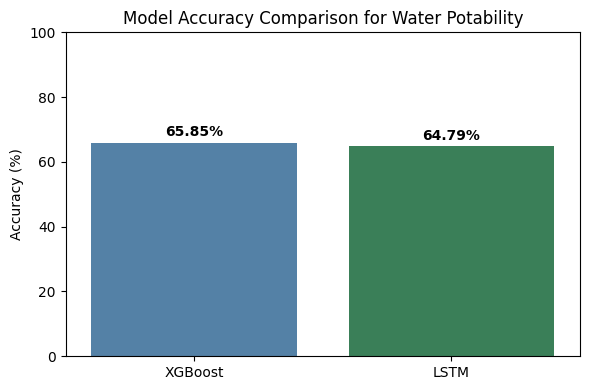

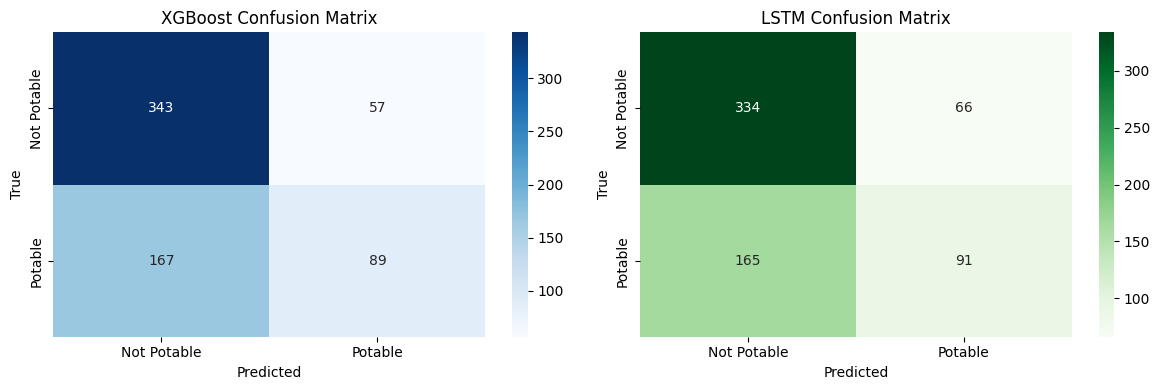


Model training, testing, and comparison complete!


In [ ]:
# STEP 7 — PERFORMANCE COMPARISON VISUALIZATION

print("\n" + "=" * 50)
print("GENERATING ACCURACY COMPARISON CHART")
print("=" * 50)

# Create Accuracy Comparison Plot
plt.figure(figsize=(6, 4))
models = ['XGBoost', 'LSTM']
accuracies = [xgb_acc * 100, lstm_acc * 100]

sns.barplot(x=models, y=accuracies, palette=['steelblue', 'seagreen'])
plt.title('Model Accuracy Comparison for Water Potability')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

for i, v in enumerate(accuracies):
    plt.text(i, v + 2, f"{v:.2f}%", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# Create Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# XGBoost Confusion Matrix
sns.heatmap(confusion_matrix(y_test, xgb_preds), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('XGBoost Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_xticklabels(['Not Potable', 'Potable'])
axes[0].set_yticklabels(['Not Potable', 'Potable'])

# LSTM Confusion Matrix
sns.heatmap(confusion_matrix(y_test, lstm_preds), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('LSTM Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].set_xticklabels(['Not Potable', 'Potable'])
axes[1].set_yticklabels(['Not Potable', 'Potable'])

plt.tight_layout()
plt.show()

print("\nModel training, testing, and comparison complete!")

**CHAPTER 9: Deployment**

In [ ]:
# STEP 8 — MODEL SERIALIZATION (DEPLOYMENT READY)

import joblib

# Create a deployment directory if it doesn't exist
os.makedirs('deployment_models', exist_ok=True)

# 1. Save the structured feature scaler - this so the number given by user can be normalize first
joblib.dump(scaler, 'deployment_models/water_scaler.pkl')
print("Scaler saved successfully! ")

# 2. Save the trained XGBoost Classifier
joblib.dump(xgb_model, 'deployment_models/xgboost_potability_model.pkl')
print("XGBoost model saved successfully! ")

# 3. Save the Keras LSTM Network architecture & weights
lstm_model.save('deployment_models/lstm_potability_model.keras')
print("LSTM Keras network saved successfully! ")

Scaler saved successfully! 
XGBoost model saved successfully! 
LSTM Keras network saved successfully! 
